In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
sns.set()

# Chargement des données
df = pd.read_csv('oasis_longitudinal.csv')  #on enlève l'url et on s'assure que le fichier est dans le même dossier que le notebook
# print("Premiers enregistrements:\n", df.head())

# Affichage du dataset
from IPython.display import display
pd.options.display.max_columns = None 
print("Dataset:\n")
display(df) #pour afficher les infos du fichier csv
df.describe() # pour avoir les infos réparties selon des caractéristiques (moyenne, écart-types,...) de chaque colonne

Dataset:



,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0,M,R,87,14,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457,M,R,88,14,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002,OAS2_0002_MR1,Demented,1,0,M,R,75,12,NaN,23.0,0.5,1678,0.736,1.046
3,OAS2_0002,OAS2_0002_MR2,Demented,2,560,M,R,76,12,NaN,28.0,0.5,1738,0.713,1.010
4,OAS2_0002,OAS2_0002_MR3,Demented,3,1895,M,R,80,12,NaN,22.0,0.5,1698,0.701,1.034
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368,OAS2_0185,OAS2_0185_MR2,Demented,2,842,M,R,82,16,1.0,28.0,0.5,1693,0.694,1.037
369,OAS2_0185,OAS2_0185_MR3,Demented,3,2297,M,R,86,16,1.0,26.0,0.5,1688,0.675,1.040
370,OAS2_0186,OAS2_0186_MR1,Nondemented,1,0,F,R,61,13,2.0,30.0,0.0,1319,0.801,1.331
371,OAS2_0186,OAS2_0186_MR2,Nondemented,2,763,F,R,63,13,2.0,30.0,0.0,1327,0.796,1.323


,Visit,MR Delay,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,373.000000,373.000000,373.000000,373.000000,354.000000,371.000000,373.000000,373.000000,373.000000,373.000000
mean,1.882038,595.104558,77.013405,14.597855,2.460452,27.342318,0.290885,1488.128686,0.729568,1.195461
std,0.922843,635.485118,7.640957,2.876339,1.134005,3.683244,0.374557,176.139286,0.037135,0.138092
min,1.000000,0.000000,60.000000,6.000000,1.000000,4.000000,0.000000,1106.000000,0.644000,0.876000
25%,1.000000,0.000000,71.000000,12.000000,2.000000,27.000000,0.000000,1357.000000,0.700000,1.099000
50%,2.000000,552.000000,77.000000,15.000000,2.000000,29.000000,0.000000,1470.000000,0.729000,1.194000
75%,2.000000,873.000000,82.000000,16.000000,3.000000,30.000000,0.500000,1597.000000,0.756000,1.293000
max,5.000000,2639.000000,98.000000,23.000000,5.000000,30.000000,2.000000,2004.000000,0.837000,1.587000


In [8]:
print("Dataset Shape:", df.shape)  #(nb de lignes, nombre de colonne)
df.info()

Dataset Shape: (373, 15)
<class 'pandas.DataFrame'>
RangeIndex: 373 entries, 0 to 372
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Subject ID  373 non-null    str    
 1   MRI ID      373 non-null    str    
 2   Group       373 non-null    str    
 3   Visit       373 non-null    int64  
 4   MR Delay    373 non-null    int64  
 5   M/F         373 non-null    str    
 6   Hand        373 non-null    str    
 7   Age         373 non-null    int64  
 8   EDUC        373 non-null    int64  
 9   SES         354 non-null    float64
 10  MMSE        371 non-null    float64
 11  CDR         373 non-null    float64
 12  eTIV        373 non-null    int64  
 13  nWBV        373 non-null    float64
 14  ASF         373 non-null    float64
dtypes: float64(5), int64(5), str(5)
memory usage: 56.1 KB


In [9]:
# Nettoyage du dataset  
df = df.loc[df['Visit']==1] 
# use first visit data only because of the analysis 
df = df.reset_index(drop=True) 
# reset index after filtering first visit data 
df['M/F'] = df['M/F'].replace(['F','M'], [0,1]) # M/F column
df['Group'] = df['Group'].replace(['Converted'], ['Demented']) # Target variable
df['Group'] = df['Group'].replace(['Demented', 'Nondemented'], [1,0]) # Target   
df = df.drop(['MRI ID', 'Visit', 'Hand'], axis=1) # Drop unnecessary columns  -  données non nécessaires pour l'étude de cas

In [10]:
df.describe()

,MR Delay,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,150.0,150.000000,150.000000,142.000000,150.00000,150.000000,150.000000,150.000000,150.000000
mean,0.0,75.446667,14.533333,2.492958,27.56000,0.260000,1474.426667,0.736073,1.206333
std,0.0,7.545421,2.874714,1.128273,2.96847,0.326256,174.683889,0.036458,0.137864
min,0.0,60.000000,6.000000,1.000000,17.00000,0.000000,1123.000000,0.660000,0.883000
25%,0.0,70.000000,12.000000,2.000000,26.00000,0.000000,1347.250000,0.710000,1.121000
50%,0.0,75.000000,14.000000,2.000000,29.00000,0.000000,1453.500000,0.735000,1.207500
75%,0.0,80.000000,16.000000,3.000000,30.00000,0.500000,1565.250000,0.757750,1.302750
max,0.0,96.000000,23.000000,5.000000,30.00000,1.000000,1987.000000,0.837000,1.563000


Text(0.5, 1.0, 'Gender and Demented rate')

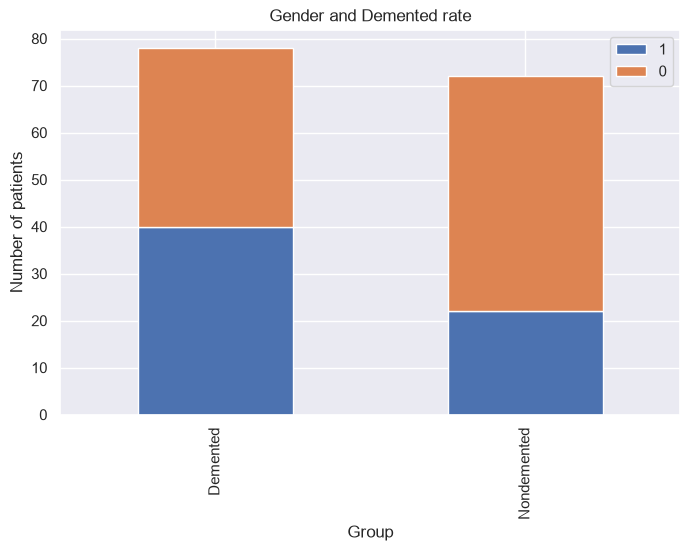

In [11]:
## GRAPH 1 - Dementia per genre
# bar drawing function
def bar_chart(feature):
    Demented = df[df['Group']==1][feature].value_counts() 
    Nondemented = df[df['Group']==0][feature].value_counts() 
    df_bar = pd.DataFrame([Demented,Nondemented]) 
    df_bar.index = ['Demented','Nondemented']
    df_bar.plot(kind='bar',stacked=True, figsize=(8,5))
# Gender and Group ( Femal=0, Male=1)
bar_chart('M/F') 
plt.xlabel('Group') 
plt.ylabel('Number of patients') 
plt.legend()
plt.title('Gender and Demented rate')

(15.3, 30.0)

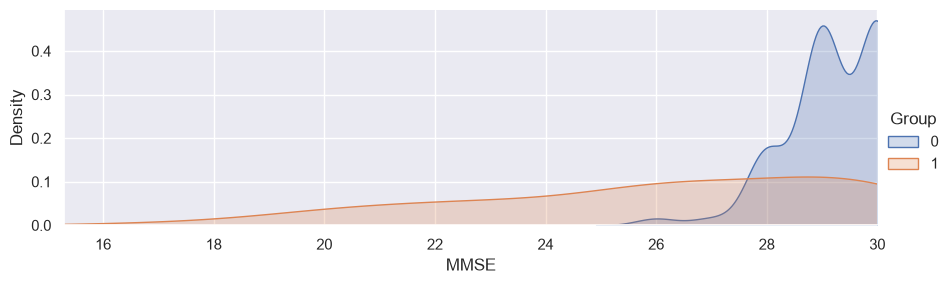

In [13]:
## GRAPH 2 - MMSE per dementia
#MMSE : Mini Mental State Examination
# Nondemented = 0, Demented =1
# Nondemented has higher test result ranging from 25 to 30. #Min 17 ,MAX 30
facet= sns.FacetGrid(df,hue="Group", aspect=3)
facet.map(sns.kdeplot,'MMSE',fill= True)
facet.set(xlim=(0, df['MMSE'].max()))
facet.add_legend()
plt.xlim(15.30)

(0.6, 0.9)

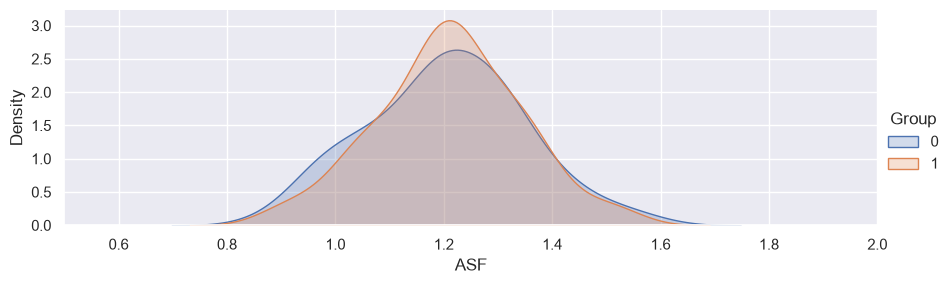

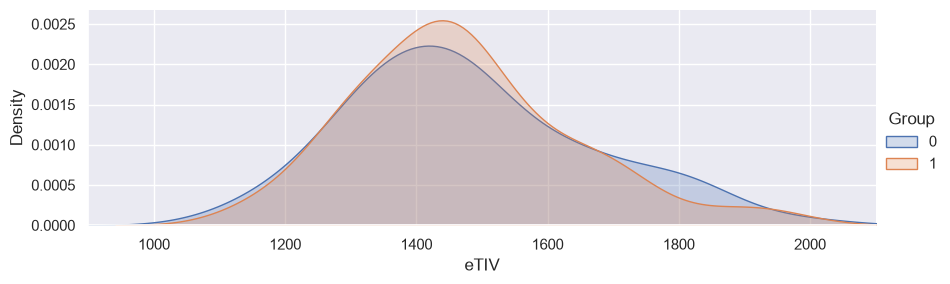

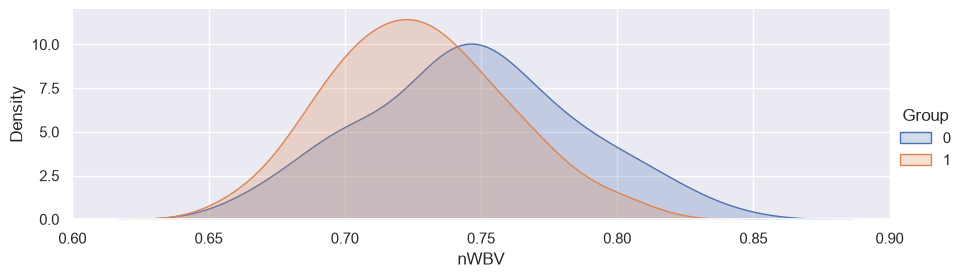

In [15]:
## GRAPH 3 - ASF, eTIV, nWBV per dementia
#bar_chart('ASF') = Atlas Scaling Factor
facet= sns.FacetGrid(df,hue="Group", aspect=3) 
facet.map(sns.kdeplot,'ASF',fill= True) 
facet.set(xlim=(0, df['ASF'].max())) 
facet.add_legend()
plt.xlim(0.5, 2)

#eTIV = Estimated Total Intracranial Volume
facet= sns.FacetGrid(df,hue="Group", aspect=3) 
facet.map(sns.kdeplot,'eTIV',fill= True) 
facet.set(xlim=(0, df['eTIV'].max())) 
facet.add_legend()
plt.xlim(900, 2100)

#'nWBV' = Normalized Whole Brain Volume
# Nondemented = 0, Demented =1
facet= sns.FacetGrid(df,hue="Group", aspect=3) 
facet.map(sns.kdeplot,'nWBV',fill= True) 
facet.set(xlim=(0, df['nWBV'].max())) 
facet.add_legend()
plt.xlim(0.6,0.9)

(0.0, 0.16)

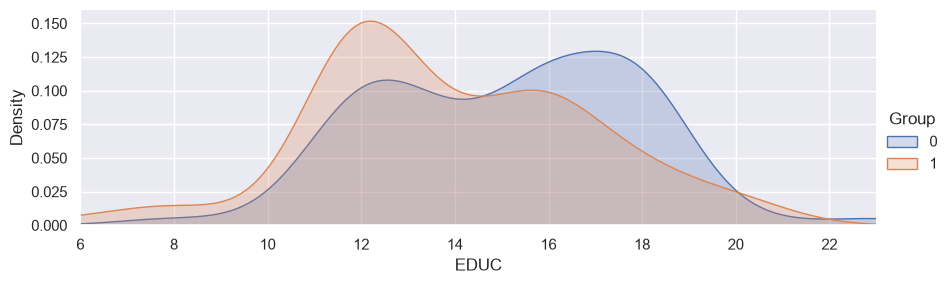

In [17]:
## GRAPH 5 - Education per dementia
#'EDUC' = Years of Education
# Nondemented = 0, Demented =1
facet= sns.FacetGrid(df,hue="Group", aspect=3) 
facet.map(sns.kdeplot,'EDUC',fill= True) 
facet.set(xlim=(df['EDUC'].min(), df['EDUC'].max())) 
facet.add_legend()
plt.ylim(0, 0.16)

In [18]:
df.describe()

,MR Delay,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,150.0,150.000000,150.000000,142.000000,150.00000,150.000000,150.000000,150.000000,150.000000
mean,0.0,75.446667,14.533333,2.492958,27.56000,0.260000,1474.426667,0.736073,1.206333
std,0.0,7.545421,2.874714,1.128273,2.96847,0.326256,174.683889,0.036458,0.137864
min,0.0,60.000000,6.000000,1.000000,17.00000,0.000000,1123.000000,0.660000,0.883000
25%,0.0,70.000000,12.000000,2.000000,26.00000,0.000000,1347.250000,0.710000,1.121000
50%,0.0,75.000000,14.000000,2.000000,29.00000,0.000000,1453.500000,0.735000,1.207500
75%,0.0,80.000000,16.000000,3.000000,30.00000,0.500000,1565.250000,0.757750,1.302750
max,0.0,96.000000,23.000000,5.000000,30.00000,1.000000,1987.000000,0.837000,1.563000


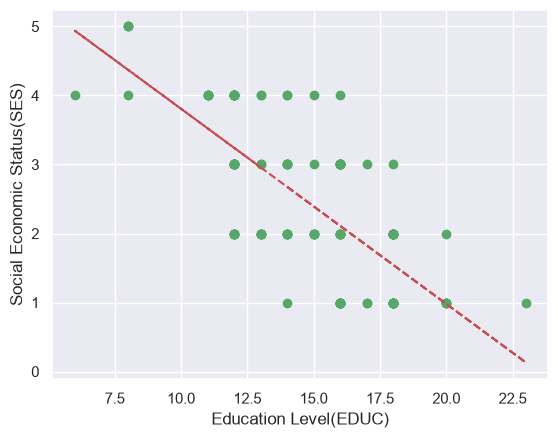

SES
False    150
Name: count, dtype: int64

In [23]:
#traitement des données

# Check missing values by each column
pd.isnull(df).sum() 
# The column, SES has 8 missing values

# Dropped the 8 rows with missing values in the column, SES
df_dropna = df.dropna(axis=0, how='any')
pd.isnull(df_dropna).sum()

df_dropna['Group'].value_counts()

# Draw scatter plot between EDUC and SES  pour remplir les valeurs manquantes avec les médianes
x = df['EDUC']
y = df['SES']

ses_not_null_index = y[~y.isnull()].index
x = x[ses_not_null_index]
y = y[ses_not_null_index]

# Draw trend line in red
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
plt.plot(x, y, 'go', x, p(x), "r--")
plt.xlabel('Education Level(EDUC)')
plt.ylabel('Social Economic Status(SES)')

plt.show()

df.groupby(['EDUC'])['SES'].median()

df.fillna({"SES" : df.groupby("EDUC")["SES"].transform("median")}, inplace=True) #fillna permet de remplir les valeurs manquantes

# I confirm there're no more missing values and all the 150 data were used.
pd.isnull(df['SES']).value_counts()

In [24]:
df.describe() #on voit que SES a maintenant 150 valeur comme les autres lignes 

,MR Delay,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,150.0,150.000000,150.000000,150.000000,150.00000,150.000000,150.000000,150.000000,150.000000
mean,0.0,75.446667,14.533333,2.513333,27.56000,0.260000,1474.426667,0.736073,1.206333
std,0.0,7.545421,2.874714,1.103604,2.96847,0.326256,174.683889,0.036458,0.137864
min,0.0,60.000000,6.000000,1.000000,17.00000,0.000000,1123.000000,0.660000,0.883000
25%,0.0,70.000000,12.000000,2.000000,26.00000,0.000000,1347.250000,0.710000,1.121000
50%,0.0,75.000000,14.000000,2.000000,29.00000,0.000000,1453.500000,0.735000,1.207500
75%,0.0,80.000000,16.000000,3.000000,30.00000,0.500000,1565.250000,0.757750,1.302750
max,0.0,96.000000,23.000000,5.000000,30.00000,1.000000,1987.000000,0.837000,1.563000


In [58]:
#préparation pour les algorithmes

## Splitting Train/Validation/Test Sets

from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.preprocessing import MinMaxScaler 
from sklearn.model_selection import cross_val_score

# Dataset with imputation
Y = df['Group'].values # Target for the model
X = df[['M/F', 'Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']] # Features we use

# splitting into three sets
X_trainval, X_test, Y_trainval, Y_test = train_test_split(X, Y, random_state=0)

# Feature scaling
scaler = MinMaxScaler().fit(X_trainval)
X_trainval_scaled = scaler.transform(X_trainval)
X_test_scaled = scaler.transform(X_test)

# Dataset after dropping missing value rows
Y = df_dropna['Group'].values # Target for the model
X = df_dropna[['M/F', 'Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']] # Features we use

# splitting into three sets
X_trainval_dna, X_test_dna, Y_trainval_dna, Y_test_dna = train_test_split(X, Y, random_state=0)

# Feature scaling
scaler = MinMaxScaler().fit(X_trainval_dna)
X_trainval_scaled_dna = scaler.transform(X_trainval_dna)
X_test_scaled_dna = scaler.transform(X_test_dna)

In [59]:
# No convergence warnings
import warnings
from sklearn.exceptions import ConvergenceWarning 
warnings.filterwarnings(action='ignore', category=ConvergenceWarning)

In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, roc_curve, auc

import time
tps_tot = time.perf_counter()

acc = [] # list to store all performance metric

In [61]:
## Logistic Regression (with imputation)

tps = time.perf_counter()

# Dataset with imputation
best_score=0
kfolds=5 # set the number of folds

Y_trainval = Y_trainval.astype(int)  #pour éviter les erreurs de types de données
Y_test = Y_test.astype(int)
                       
for c in [0.001, 0.1, 1, 10, 100]:
    logRegModel = LogisticRegression(C=c)
    # perform cross-validation
    
    # Get recall for each parameter setting
    scores = cross_val_score(logRegModel, X_trainval, Y_trainval, cv=kfolds, scoring='accuracy') #score = les erreurs de la cross validation
    
    # compute mean cross-validation accuracy
    score = np.mean(scores)
    
    # Find the best parameters and score
    if score > best_score:
        best_score = score
        best_parameters = c

# rebuild a model on the combined training and validation set
SelectedLogRegModel = LogisticRegression(C=best_parameters).fit(X_trainval_scaled, Y_trainval)

test_score = SelectedLogRegModel.score(X_test_scaled, Y_test)
PredictedOutput = SelectedLogRegModel.predict(X_test_scaled)
test_recall = recall_score(Y_test, PredictedOutput, pos_label=1)
fpr, tpr, thresholds = roc_curve(Y_test, PredictedOutput, pos_label=1)
test_auc = auc(fpr, tpr)
print("Best accuracy on validation set is:", best_score)
print("Best parameter for regularization (C) is: ", best_parameters)
print("Test accuracy with best C parameter is", test_score)
print("Test recall with the best C parameter is", test_recall)
print("Test AUC with the best C parameter is", test_auc)
m = 'Logistic Regression (w/ imputation)'
executionTime = "{:.2f}".format(time.perf_counter()-tps)
acc.append([m, test_score, test_recall, test_auc, executionTime, fpr, tpr, thresholds])
print("Execution time:", executionTime, "seconds")

Best accuracy on validation set is: 0.7158102766798419
Best parameter for regularization (C) is:  10
Test accuracy with best C parameter is 0.7631578947368421
Test recall with the best C parameter is 0.7
Test AUC with the best C parameter is 0.7666666666666667
Execution time: 0.96 seconds


In [62]:

## Logistic Regression (with drop n/a)

tps = time.perf_counter()

# Dataset after dropping missing value rows
best_score=0
kfolds=5 # set the number of folds

Y_trainval_dna = Y_trainval_dna.astype(int) 
Y_test_dna = Y_test_dna.astype(int)
Y_trainval = Y_trainval.astype(int)
Y_test = Y_test.astype(int)
for c in [0.001, 0.1, 1, 10, 100]:
    logRegModel = LogisticRegression(C=c)
    # perform cross-validation
    scores = cross_val_score(logRegModel, X_trainval_scaled_dna, Y_trainval_dna, cv=kfolds, scoring='accuracy')
    
    # compute mean cross-validation accuracy
    score = np.mean(scores)
    
    # Find the best parameters and score
    if score > best_score:
        best_score = score
        best_parameters = c

# rebuild a model on the combined training and validation set
SelectedLogRegModel = LogisticRegression(C=best_parameters).fit(X_trainval_scaled_dna, Y_trainval_dna)

test_score = SelectedLogRegModel.score(X_test_scaled_dna, Y_test_dna)
PredictedOutput = SelectedLogRegModel.predict(X_test_scaled)
test_recall = recall_score(Y_test, PredictedOutput, pos_label=1)
fpr, tpr, thresholds = roc_curve(Y_test, PredictedOutput, pos_label=1)
test_auc = auc(fpr, tpr)
print("Best accuracy on validation set is:", best_score)
print("Best parameter for regularization (C) is: ", best_parameters)
print("Test accuracy with best C parameter is", test_score)        
print("Test recall with the best C parameter is", test_recall)
print("Test AUC with the best C parameter is", test_auc)

m = 'Logistic Regression (w/ dropna)'
executionTime = "{:.2f}".format(time.perf_counter()-tps)
acc.append([m, test_score, test_recall, test_auc, executionTime, fpr, tpr, thresholds])
print("Execution time:", executionTime, "seconds")

Best accuracy on validation set is: 0.725974025974026
Best parameter for regularization (C) is:  10
Test accuracy with best C parameter is 0.8055555555555556
Test recall with the best C parameter is 0.75
Test AUC with the best C parameter is 0.8194444444444443
Execution time: 0.29 seconds


In [63]:
## RESULTS
# Performance Metric for each model
result = pd.DataFrame(acc, columns=['Model', 'Accuracy', 'Recall', 'AUC', 'executionTime', 'FPR', 'TPR', 'TH'])
a = np.array(result[['Model', 'Accuracy', 'Recall', 'AUC', 'executionTime']])
a = a[a[:, 4].argsort()]
a = a[a[:, 3].argsort()]
a = a[a[:, 2].argsort()]
a = a[a[:, 1].argsort(kind='mergesort')[::-1]]
result = pd.DataFrame(a.tolist(), columns=['Model', 'Accuracy', 'Recall', 'AUC', 'executionTime'])
result

,Model,Accuracy,Recall,AUC,executionTime
0,Logistic Regression (w/ dropna),0.805556,0.75,0.819444,0.29
1,Logistic Regression (w/ imputation),0.763158,0.70,0.766667,0.96


In [64]:
#analyse discriminante linéaire

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, roc_curve, auc

tps = time.perf_counter()

kfolds=5 # set the number of folds
best_score=0

logDiscriminantAnalysis = LinearDiscriminantAnalysis()
# perform cross-validation
scores = cross_val_score(logDiscriminantAnalysis, X_trainval_scaled_dna, Y_trainval_dna, cv=kfolds, scoring='accuracy')   
# compute mean cross-validation accuracy
score = np.mean(scores)

print()
# rebuild a model on the combined training and validation set
SelectedDiscriminantAnalysisModel = LinearDiscriminantAnalysis().fit(X_trainval_scaled_dna, Y_trainval_dna)

test_score_lda = SelectedDiscriminantAnalysisModel.score(X_test_scaled_dna, Y_test_dna)
PredictedOutput_lda = SelectedDiscriminantAnalysisModel.predict(X_test_scaled)
test_recall_lda = recall_score(Y_test, PredictedOutput_lda, pos_label=1)
fpr_lda, tpr_lda, thresholds_lda = roc_curve(Y_test, PredictedOutput_lda, pos_label=1)
test_auc_lda = auc(fpr_lda, tpr_lda)
print("Test accuracy is", test_score_lda)        
print("Test recall is", test_recall_lda)
print("Test AUC is", test_auc_lda)

m = 'Linear Discriminant Analysis'
executionTime = "{:.2f}".format(time.perf_counter()-tps)
acc.append([m, test_score_lda, test_recall_lda, test_auc_lda, fpr_lda, tpr_lda, thresholds_lda])
print("Execution time:", executionTime, "seconds")


Test accuracy is 0.75
Test recall is 0.75
Test AUC is 0.8194444444444443
Execution time: 0.06 seconds


In [65]:
#analyse discriminante quadratique 

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

tps = time.perf_counter()
kfolds=5 # set the number of folds
best_score=0

logQuadraticDiscriminantAnalysis = QuadraticDiscriminantAnalysis()
# perform cross-validation
scores = cross_val_score(logQuadraticDiscriminantAnalysis, X_trainval_scaled_dna, Y_trainval_dna, cv=kfolds, scoring='accuracy')   
# compute mean cross-validation accuracy
score = np.mean(scores)

# rebuild a model on the combined training and validation set
SelectedQuadraticDiscriminantAnalysisModel = QuadraticDiscriminantAnalysis().fit(X_trainval_scaled_dna, Y_trainval_dna)

test_score_qda = SelectedQuadraticDiscriminantAnalysisModel.score(X_test_scaled_dna, Y_test_dna)
PredictedOutput_qda = SelectedQuadraticDiscriminantAnalysisModel.predict(X_test_scaled)
test_recall_qda = recall_score(Y_test, PredictedOutput_qda, pos_label=1)
fpr_qda, tpr_qda, thresholds_qda = roc_curve(Y_test, PredictedOutput_qda, pos_label=1)
test_auc_qda = auc(fpr_qda, tpr_qda)
print("Test accuracy is", test_score_qda)        
print("Test recall is", test_recall_qda)
print("Test AUC is", test_auc_qda)

m = 'Quadratic Discriminant Analysis'
executionTime = "{:.2f}".format(time.perf_counter()-tps)
acc.append([m, test_score_qda, test_recall_qda, test_auc_qda, fpr_qda, tpr_qda, thresholds_qda])
print("Execution time:", executionTime, "seconds")

Test accuracy is 0.8888888888888888
Test recall is 0.8
Test AUC is 0.8722222222222222
Execution time: 0.04 seconds


In [67]:
#kernel ridge 

from sklearn.kernel_ridge import KernelRidge
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, roc_curve, auc
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pathToData = 'oasis_longitudinal.csv'
sns.set()

df = pd.read_csv(pathToData)
df = df.loc[df['Visit']==1] # use first visit data only because of the analysis we're doing
df = df.reset_index(drop=True) # reset index after filtering first visit data
df['M/F'] = df['M/F'].replace(['F','M'], [0,1]) # M/F column
df['Group'] = df['Group'].replace(['Converted'], ['Demented']) # Target variable
df['Group'] = df['Group'].replace(['Demented', 'Nondemented'], [1,0]) # Target variable
df = df.drop(['MRI ID', 'Visit', 'Hand'], axis=1) # Drop unnecessary columns

# The column, SES has 8 missing values

# Dropped the 8 rows with missing values in the column, SES
df_dropna = df.dropna(axis=0, how='any')
pd.isnull(df_dropna).sum()
df_dropna['M/F'].value_counts()


# Dataset with imputation
Y = df['Group'].values # Target for the model
X = df[['M/F', 'Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']] # Features we use

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler 
from pylab import *
from sklearn.model_selection import cross_val_score
# splitting into three sets
X_trainval, X_test, Y_trainval, Y_test = train_test_split(X, Y, random_state=0)

# Feature scaling
scaler = MinMaxScaler().fit(X_trainval)
X_trainval_scaled = scaler.transform(X_trainval)
X_test_scaled = scaler.transform(X_test)


# Dataset after dropping missing value rows
Y = df_dropna['Group'].values # Target for the model
X = df_dropna[['M/F', 'Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']] # Features we use

# splitting into three sets
X_trainval_dna, X_test_dna, Y_trainval_dna, Y_test_dna = train_test_split(
    X, Y, random_state=0)

# Feature scaling
scaler = MinMaxScaler().fit(X_trainval_dna)
X_trainval_scaled_dna = scaler.transform(X_trainval_dna)
X_test_scaled_dna = scaler.transform(X_test_dna)



clf = KernelRidge(alpha=1.0)
clf.fit(X_trainval_scaled_dna, Y_trainval_dna)
KernelRidge(alpha=1.0)
clf.get_params(deep=True)
PredictedOutput_qda = clf.predict(X_test_scaled_dna)
score_krr = clf.score(X_test_scaled_dna, Y_test_dna, sample_weight=None)
print("------- Kernel Ridge Regression ------- ")
print("Test coefficient de détermination", score_krr)        

------- Kernel Ridge Regression ------- 
Test coefficient de détermination 0.19289985628451145


In [68]:
print("PredictedOutput_qda")   
print(PredictedOutput_qda)

PredictedOutput_discrete_qda = []
for x in PredictedOutput_qda:
    if x < 0.5:
        PredictedOutput_discrete_qda.append(0)
    else:
        PredictedOutput_discrete_qda.append(1)
print("===========================")   
print("PredictedOutput_discrete_qda")       
print(PredictedOutput_discrete_qda)
print(shape(PredictedOutput_discrete_qda))
print("===========================")   
print("Y_test_dna")    
print(Y_test_dna)
print(shape(Y_test_dna))

PredictedOutput_qda
[0.24158741 1.01947253 0.77742566 0.46819655 1.12794498 0.50459349
 0.49379992 0.59789325 0.73325938 0.33867668 0.3308208  0.88629921
 0.91466226 0.38160723 0.53891292 0.28833336 0.68502834 0.61697907
 0.27894832 0.43417797 0.68788487 0.63929595 0.55654633 0.76510588
 0.53978714 0.76760267 0.11716476 0.54431386 0.30079872 0.52854942
 0.69075903 0.60836997 0.51562754 0.59498234 0.55085573 0.26914113]
PredictedOutput_discrete_qda
[0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0]
(36,)
Y_test_dna
[0 1 1 1 1 0 0 1 0 0 0 1 1 0 1 0 0 1 1 0 1 1 0 1 1 1 0 0 0 0 0 1 0 0 0 1]
(36,)


In [71]:
pred_correct = 0
Y_trainval_dna = Y_trainval_dna.astype(int) 
Y_test_dna = Y_test_dna.astype(int)
for i in range(len(PredictedOutput_discrete_qda)):
    if PredictedOutput_discrete_qda[i] == Y_test_dna[i]:
        pred_correct += 1
score = pred_correct / len(PredictedOutput_discrete_qda)
print(score)

0.6388888888888888


In [72]:
test_recall_qda = recall_score(Y_test_dna, PredictedOutput_discrete_qda, pos_label=1)
fpr_qda, tpr_qda, thresholds_qda = roc_curve(Y_test_dna, PredictedOutput_discrete_qda, pos_label=1)
test_auc_qda = auc(fpr_qda, tpr_qda)
print("Test accuracy is", score)        
print("Test recall is", test_recall_qda)
print("Test AUC is", test_auc_qda)

m = 'Kernel Ridge'
acc.append([m, score, test_recall_qda, test_auc_qda, fpr_qda, tpr_qda, thresholds_qda])

Test accuracy is 0.6388888888888888
Test recall is 0.8235294117647058
Test AUC is 0.6486068111455108


In [75]:
#support vector machine

from sklearn import svm

best_score = 0
k_parameter = 'rbf'

Y_trainval_dna = Y_trainval_dna.astype(int) 
Y_test_dna = Y_test_dna.astype(int)
Y_trainval = Y_trainval.astype(int)
Y_test = Y_test.astype(int)

for c_paramter in [0.001, 0.01, 0.1, 1, 10, 100, 1000]: #iterate over the values we need to try for the parameter C
    for gamma_paramter in [0.001, 0.01, 0.1, 1, 10, 100, 1000]: #iterate over the values we need to try for the parameter gamma
#        for k_parameter in ['rbf', 'linear', 'poly', 'sigmoid']: # iterate over the values we need to try for the kernel parameter
            svmModel = SVC(kernel=k_parameter, C=c_paramter, gamma=gamma_paramter) #define the model
            # perform cross-validation
            scores = cross_val_score(svmModel, X_trainval_scaled_dna, Y_trainval_dna, cv=kfolds, scoring='accuracy')
            # the training set will be split internally into training and cross validation

            # compute mean cross-validation accuracy
            score = np.mean(scores)
            # if we got a better score, store the score and parameters
            if score > best_score:
                best_score = score #store the score 
                best_parameter_c = c_paramter #store the parameter c
                best_parameter_gamma = gamma_paramter #store the parameter gamma
                best_parameter_k = k_parameter

print("=========================")                
print("Performance SVM noyau RBF")
print("Best accuracy on cross validation set is:", best_score)
print("Best parameter for c is: ", best_parameter_c)
print("Best parameter for gamma is: ", best_parameter_gamma)
# print("Best parameter for kernel is: ", best_parameter_k)

from sklearn import svm
               
# rebuild a model with best parameters to get score 
SelectedSVMmodel = SVC(C=best_parameter_c, gamma=best_parameter_gamma, kernel='rbf').fit(X_trainval_scaled_dna, Y_trainval_dna)

test_score = SelectedSVMmodel.score(X_test_scaled, Y_test)
PredictedOutput = SelectedSVMmodel.predict(X_test_scaled)
test_recall = recall_score(Y_test, PredictedOutput, pos_label=1)
fpr, tpr, thresholds = roc_curve(Y_test, PredictedOutput, pos_label=1)
test_auc = auc(fpr, tpr)

#print("Best accuracy on cross validation set is:", best_score)
#print("Best parameter for c is: ", best_parameter_c)
#print("Best parameter for gamma is: ", best_parameter_gamma)
#print("Best parameter for kernel is: ", best_parameter_k)
print("Test accuracy with the best parameters is", test_score)
print("Test recall with the best parameters is", test_recall)
print("Test AUC with the best parameter is", test_auc)

m = 'SVM'
acc.append([m, test_score, test_recall, test_auc, fpr, tpr, thresholds])

Performance SVM noyau RBF
Best accuracy on cross validation set is: 0.7354978354978355
Best parameter for c is:  1000
Best parameter for gamma is:  0.01
Test accuracy with the best parameters is 0.8421052631578947
Test recall with the best parameters is 0.8
Test AUC with the best parameter is 0.8444444444444443


In [76]:
#k plus proches voisins

from sklearn import neighbors

best_score = 0
for k_paramter in range(1, 5): #iterate over the values we need to try for the hyperparameter k
        neigh = neighbors.KNeighborsClassifier(n_neighbors=k_paramter)
        neigh.fit(X_trainval_scaled_dna, Y_trainval_dna)
        # perform cross-validation
        scores = cross_val_score(neigh, X_trainval_scaled_dna, Y_trainval_dna, cv=kfolds, scoring='accuracy')
        # the training set will be split internally into training and cross validation

        # compute mean cross-validation accuracy
        score = np.mean(scores)
        # if we got a better score, store the score and parameters
        if score > best_score:
            best_score = score #store the score 
            best_parameter_k = k_paramter #store the parameter k
print("==========================")
print("Performance KNN")            
print("Best accuracy on cross validation set is:", best_score)
print("Best hyperparameter for k is: ", best_parameter_k)

from sklearn import svm              
# rebuild a model with best parameters to get score 
neigh = neighbors.KNeighborsClassifier(n_neighbors=best_parameter_k)
neigh.fit(X_test_scaled, Y_test)
test_score = neigh.score(X_test_scaled, Y_test)
PredictedOutput = neigh.predict(X_test_scaled)
test_recall = recall_score(Y_test, PredictedOutput, pos_label=1)
fpr, tpr, thresholds = roc_curve(Y_test, PredictedOutput, pos_label=1)
test_auc = auc(fpr, tpr)
print("Test accuracy with the best parameters is", test_score)
print("Test recall with the best parameters is", test_recall)
print("Test AUC with the best parameter is", test_auc)

m = 'KNN'
acc.append([m, test_score, test_recall, test_auc, fpr, tpr, thresholds])

Performance KNN
Best accuracy on cross validation set is: 0.6411255411255412
Best hyperparameter for k is:  3
Test accuracy with the best parameters is 0.868421052631579
Test recall with the best parameters is 0.95
Test AUC with the best parameter is 0.8638888888888888
